# Сравнение эвристик A* на восьмисвязной сетке

Лабораторная работа № 4. Исследуется влияние эвристики на оптимальность
найденного пути, число раскрытий вершин и время поиска.

Сравниваются расстояния Евклида, Octile, Чебышёва и Манхэттена на трёх
картах MovingAI. Для каждой карты выбрано 100 задач; всего выполнено
1200 измеряемых запусков. Движение разрешено в восьми направлениях
без срезания углов: прямой шаг стоит 1, диагональный — √2.

## 1. Параметры и воспроизводимость

Все эвристики решают одинаковые пары старт/цель. Используется A* с
повторным открытием вершин и фиксированным tie-break `g_max`: при равных
`f` предпочтение отдаётся большему `g`. Seed отбора задач и порядка
эвристик равен 42. На каждую пару задача/эвристика выполнен один замер.

По умолчанию загружаются сохранённые измерения из `results/`, поэтому
повторное открытие отчёта не заменяет результаты эксперимента.
Для нового измерения установите `RUN_FULL_BENCHMARK = True` и выполните
ноутбук сверху вниз. Карты и сценарии находятся в `data/`; интернет для
запуска не требуется.

In [1]:
from pathlib import Path
from time import perf_counter
from heapq import heappop, heappush
from typing import Tuple, List, Iterable, Callable, Type, Dict, Union, Optional
from datetime import datetime, timezone
import hashlib
import json
import math
import platform

import numpy as np
import numpy.typing as npt
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image, ImageDraw
from IPython.display import display, Markdown

%matplotlib inline

SEED = 42
TASKS_PER_MAP = 100
REPEATS = 1
TIE_BREAK = 'g_max'  # одинаковый для всех четырёх эвристик
RUN_FULL_BENCHMARK = False
PATH_TOL = 1e-5  # .scen хранит эталонную длину с конечной точностью

root_candidates = [
    Path.cwd(),
    Path.cwd() / 'lab04-benchmarking-astar',
    Path.cwd() / 'labs-astar' / 'lab04-benchmarking-astar',
]
BASE_DIR = next(
    (path for path in root_candidates if (path / 'data' / 'sources.json').is_file()),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError('Открой ноутбук из папки lab04-benchmarking-astar или labs-astar.')
DATA_DIR = BASE_DIR / 'data'
RESULTS_DIR = BASE_DIR / 'results'

HEURISTIC_ORDER = ['Euclidean', 'Octile', 'Chebyshev', 'Manhattan']
HEURISTIC_COLORS = {
    'Euclidean': '#4477AA', 'Octile': '#CCBB44',
    'Chebyshev': '#228833', 'Manhattan': '#AA3377',
}
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False,
})

print('Python:', platform.python_version())
print('Режим:', 'новый эксперимент' if RUN_FULL_BENCHMARK else 'сохранённые измерения')

Python: 3.12.3
Режим: сохранённые измерения


## 2. Модель карты и стоимость перехода

Клетки задаются координатами `(i, j)`: строка и столбец. Препятствия
непроходимы. Диагональный переход разрешён только при свободной целевой
клетке и обеих клетках, прилегающих к диагонали по сторонам.

In [2]:
class Map:

    def __init__(self, cells: npt.NDArray):
        self._width = cells.shape[1]
        self._height = cells.shape[0]
        self._cells = cells

    def in_bounds(self, i: int, j: int) -> bool:
        return (0 <= j < self._width) and (0 <= i < self._height)

    def traversable(self, i: int, j: int) -> bool:
        return not self._cells[i, j]

    def get_neighbors(self, i: int, j: int) -> List[Tuple[int, int]]:
        res  = []
        for di, dj in [(-1,-1),(-1,0), (0,-1), (0,1), (1,0), (1,1), (-1,1), (1,-1)]:
            if self.in_bounds(i+di, j+dj) and self.traversable(i+di, j+dj) and self.traversable(i, j+dj)  and self.traversable(i+di, j):
                res.append((i+di, j+dj))
        return res

    def get_size(self) -> Tuple[int, int]:
        return (self._height, self._width)

In [3]:
def compute_cost(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:
    d =  math.sqrt((i2 - i1) ** 2 + (j2 - j1) ** 2)
    if  d > math.sqrt(2) or d == 0:
        raise ValueError(f'Invalid input ({i1}, {j1}, {i2}, {j2})')
    return d

## 3. Реализация A*

Приоритет вершины равен `f = g + h`. В OPEN хранится очередь кандидатов,
в CLOSED — обработанные вершины. Если к обработанной вершине найден
путь с меньшим `g`, она открывается повторно. Устаревшие копии в очереди
пропускаются при извлечении. По ссылкам `parent` восстанавливается маршрут.

In [4]:
class Node:

    def __init__(
        self,
        i: int,
        j: int,
        g: Union[float, int] = 0,
        h: Union[float, int] = 0,
        f: Union[float, int] = None,
        parent: "Node" = None,
    ):
        self.i = i
        self.j = j
        self.g = g
        self.h = h
        if f is None:
            self.f = self.g + h
        else:
            self.f = f
        self.parent = parent

    def __eq__(self, other):

        return (self.i == other.i) and (self.j == other.j)

    def __hash__(self):

        return hash((self.i, self.j))

    def __lt__(self, other):

        return self.f < other.f

In [5]:
class SearchTreePQDReexp: # SearchTree with reexpansion which uses priority queue for OPEN and dict for CLOSED

    def __init__(self):
        self._open = []                 # prioritized queue for the OPEN nodes
        self._closed = dict()           # dict for the expanded (at least once) nodes = CLOSED
                                        # We need dict as we want to get access to the g-value of node in the container
                                        # and set() does not allow this.
        self._reexpanded = set()        # set for the nodes that were expanded at least twice
                                        # just for illustrative purposes
        self._reopened = set()          # set for the re-open nodes (just for the illustrative purposes)

        self._enc_open_dublicates = 0    # the number of dublicates encountered in OPEN
        self._number_of_reexpansions = 0 # the number of the re-expansions

    def __len__(self):
        return len(self._open) + len(self._closed)

    def open_is_empty(self):

        return len(self._open) == 0

    def add_to_open(self, item: Node):

        old = self._closed.get(item)

        if old is not None:
            if item.g >= old.g:
                return
            del self._closed[item]
            self._reopened.add(item)

        heappush(self._open, item)

    def get_best_node_from_open(self) -> Optional[Node]:

        while self._open:

            v = heappop(self._open)
            if v in self._closed:
                self._enc_open_dublicates += 1
            else:
                if v in self._reopened:
                    self._reexpanded.add(v)
                    self._number_of_reexpansions += 1
                return v
        return None

    def add_to_closed(self, item: Node):

        self._closed[item] = item

    def was_expanded(self, item: Node) -> bool:

        return self._closed.get(item) is not None

    @property
    def opened(self):
        return self._open

    @property
    def expanded(self):
        return self._closed.values()

    @property
    def number_of_open_dublicates(self):
        return self._enc_open_dublicates

    @property
    def reexpanded(self):
        return self._reexpanded

    @property
    def number_of_reexpansions(self):
        return self._number_of_reexpansions

In [6]:
def make_path(goal: Node) -> Tuple[List[Node], Union[float, int]]:

    length = goal.g
    current = goal
    path = []
    while current.parent:
        path.append(current)
        current = current.parent
    path.append(current)
    return path[::-1], length

In [7]:
def astar_reexpansion(task_map: Map,
             start_i: int, start_j: int,
             goal_i: int, goal_j: int,
             heuristic_func: Callable,
             search_tree: Type[SearchTreePQDReexp]) -> Tuple[bool,
                                                        Optional[Node],
                                                        int,
                                                        int,
                                                        Optional[Iterable[Node]],
                                                        Optional[Iterable[Node]],
                                                        Optional[Iterable[Node]]]:
    ast = search_tree()
    steps = 0
    search_tree_size = 0

    start_node = Node(start_i, start_j, g=0, h=heuristic_func(start_i, start_j, goal_i, goal_j))
    ast.add_to_open(start_node)
    while not ast.open_is_empty():
        steps += 1
        node = ast.get_best_node_from_open()
        if node is None:
            break
        search_tree_size = len(ast)
        if node.i == goal_i and node.j == goal_j:
            return True, node, steps, search_tree_size, ast.opened, ast.expanded, ast.reexpanded
        else:
            ast.add_to_closed(node)
            for neighbor in task_map.get_neighbors(node.i, node.j):
                neighbor_node = Node(
                    neighbor[0],
                    neighbor[1],
                    g=node.g + compute_cost(node.i, node.j, neighbor[0], neighbor[1]),
                    h=heuristic_func(neighbor[0], neighbor[1], goal_i, goal_j),
                    parent=node,
                )
                ast.add_to_open(neighbor_node)

    CLOSED = ast.expanded
    search_tree_size = len(ast)
    return False, None, steps, search_tree_size, None, CLOSED, ast.reexpanded

In [8]:
def lt_g_max(self, other):
    if self.f == other.f:
        return self.g > other.g
    return self.f < other.f

def lt_g_min(self, other):
    if self.f == other.f:
        return self.g < other.g
    return self.f < other.f

In [9]:
if TIE_BREAK == 'g_max':
    Node.__lt__ = lt_g_max
elif TIE_BREAK == 'g_min':
    Node.__lt__ = lt_g_min
else:
    raise ValueError('TIE_BREAK должен быть g_max или g_min')

## 4. Эвристики

Все четыре функции оценивают оставшуюся стоимость без учёта препятствий.
Евклидова, Octile и Чебышёва допустимы для используемой модели движения.
Манхэттенская эвристика может завышать стоимость, поскольку диагональ
дешевле двух прямых шагов; для неё оптимальность результата проверяется
по эталону наравне с остальными версиями.

In [10]:
def manhattan_distance(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:

    return abs(i1 - i2) + abs(j1 - j2)

In [11]:
def euclidean_distance(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:
    return math.sqrt((i2 - i1) ** 2 + (j2 - j1) ** 2)

In [12]:
def octile_distance(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:
    a,b = min(abs(i2 - i1), abs(j2 - j1)), max(abs(i2 - i1), abs(j2 - j1))

    return a * math.sqrt(2) + (b-a)

In [13]:
def chebyshev_distance(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:
    a,b = min(abs(i2 - i1), abs(j2 - j1)), max(abs(i2 - i1), abs(j2 - j1))

    return b

In [14]:
HEURISTICS = {
    'Euclidean': euclidean_distance,
    'Octile': octile_distance,
    'Chebyshev': chebyshev_distance,
    'Manhattan': manhattan_distance,
}

## 5. Карты и выбор задач

| Карта | Коллекция MovingAI | Строки × столбцы |
|---|---|---|
| `arena` | Dragon Age: Origins | 49 × 49 |
| `ht_chantry` | Dragon Age 2 | 141 × 162 |
| `AR0021SR` | Baldur's Gate II, исходные размеры | 64 × 60 |

Карты представляют открытую площадку с препятствиями, систему помещений
и проходов, а также область неправильной формы. Небольшие размеры
ограничивают продолжительность эксперимента.

Из `.scen` считываются пары старт/цель и эталонные стоимости кратчайших
путей для диагональных переходов √2 без срезания углов. Координаты
`x, y` переводятся в `i, j = y, x`. Точные источники и контрольные суммы
файлов находятся в `data/sources.json`.

Для каждой карты сценарии сортируются по эталонной стоимости пути и
разделяются на пять примерно равных групп. Из каждой группы выбирается
20 задач без повторов. Это охватывает короткие, средние и длинные маршруты,
но не гарантирует равномерного распределения вычислительной сложности.

In [15]:
MAP_SPECS = [
    {'name': 'arena', 'collection': 'dao', 'map_file': 'arena.map', 'scen_file': 'arena.map.scen'},
    {'name': 'ht_chantry', 'collection': 'da2', 'map_file': 'ht_chantry.map', 'scen_file': 'ht_chantry.map.scen'},
    {'name': 'AR0021SR', 'collection': 'bgmaps', 'map_file': 'AR0021SR.map', 'scen_file': 'AR0021SR.map.scen'},
]


def load_movingai_map(path):
    lines = Path(path).read_text(encoding='utf-8').splitlines()
    if lines[0].strip() != 'type octile' or lines[3].strip() != 'map':
        raise ValueError(f'Неизвестный формат карты: {path}')
    height, width = int(lines[1].split()[1]), int(lines[2].split()[1])
    rows = lines[4:]
    if len(rows) != height or any(len(row) != width for row in rows):
        raise ValueError(f'Размер карты не совпадает с заголовком: {path}')
    chars = set(''.join(rows))
    if not chars <= set('.G@OT'):
        raise ValueError(f'Здесь поддерживаются обычные карты без особых типов местности: {chars}')
    cells = np.array([[0 if char in '.G' else 1 for char in row] for row in rows], dtype=np.int8)
    return Map(cells)


def load_movingai_scenarios(path, expected_map, grid_map):
    lines = Path(path).read_text(encoding='utf-8').splitlines()
    if not lines[0].startswith('version '):
        raise ValueError(f'Нет заголовка scenario: {path}')
    tasks = []
    height, width = grid_map.get_size()
    for task_id, line in enumerate(lines[1:]):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) != 9:
            raise ValueError(f'В строке scenario должно быть 9 полей: {line}')
        bucket, map_name, map_width, map_height, sx, sy, gx, gy, optimal = parts
        if Path(map_name).name != expected_map or (int(map_height), int(map_width)) != (height, width):
            raise ValueError('Сценарий относится к другой карте или масштабу')
        start, goal = (int(sy), int(sx)), (int(gy), int(gx))
        for i, j in [start, goal]:
            if not grid_map.in_bounds(i, j) or not grid_map.traversable(i, j):
                raise ValueError('Старт или цель лежит за картой либо на стене')
        length = float(optimal)
        if not math.isfinite(length) or length < 0:
            raise ValueError('Некорректная эталонная длина')
        tasks.append({'task_id': task_id, 'bucket': int(bucket), 'start': start, 'goal': goal, 'optimal_length': length})
    return tasks


maps, all_tasks = {}, {}
for spec in MAP_SPECS:
    folder = DATA_DIR / spec['collection']
    grid_map = load_movingai_map(folder / spec['map_file'])
    maps[spec['name']] = grid_map
    all_tasks[spec['name']] = load_movingai_scenarios(folder / spec['scen_file'], spec['map_file'], grid_map)

with (DATA_DIR / 'sources.json').open(encoding='utf-8') as file:
    DATA_SOURCES = json.load(file)
for source in DATA_SOURCES['files']:
    current_hash = hashlib.sha256((BASE_DIR / source['path']).read_bytes()).hexdigest()
    if current_hash != source['sha256']:
        raise ValueError(f"Изменился файл данных: {source['path']}")
print('Загружено карт:', len(maps))

Загружено карт: 3


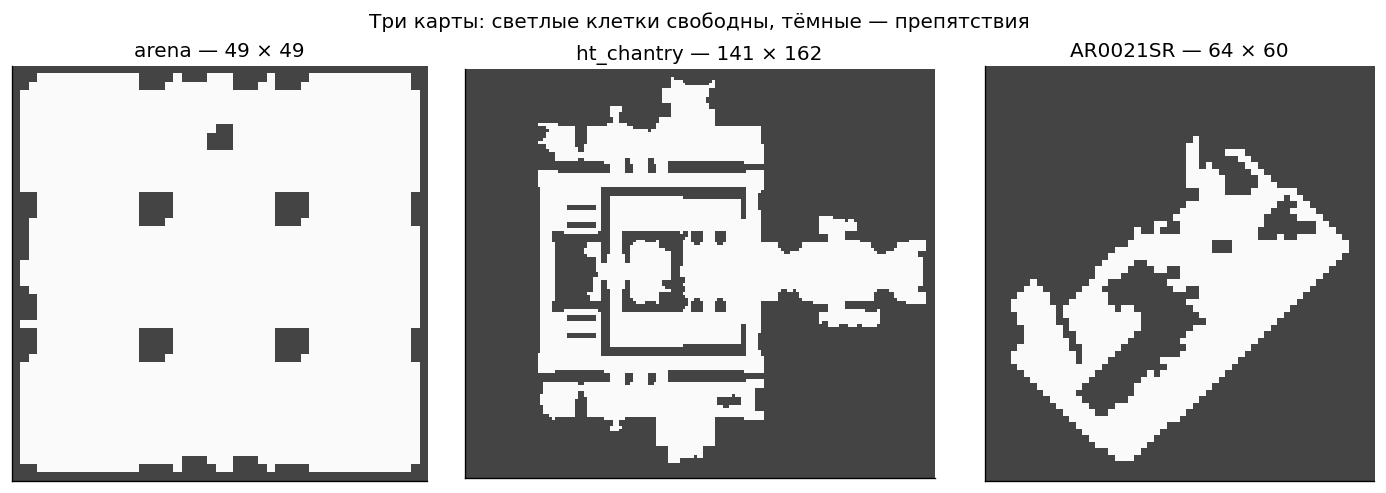

In [16]:
fig, axes = plt.subplots(1, len(maps), figsize=(12, 4), constrained_layout=True)
for ax, (name, grid_map) in zip(np.atleast_1d(axes), maps.items()):
    ax.imshow(grid_map._cells, cmap=ListedColormap(['#FAFAFA', '#444444']), vmin=0, vmax=1, interpolation='nearest')
    height, width = grid_map.get_size()
    ax.set_title(f'{name} — {height} × {width}')
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle('Три карты: светлые клетки свободны, тёмные — препятствия')
plt.show()

In [17]:
def select_tasks(tasks, n, seed):
    if n < 5 or n > len(tasks):
        raise ValueError(f'Нужно от 5 до {len(tasks)} задач, получено {n}')
    ordered = sorted(tasks, key=lambda task: (task['optimal_length'], task['task_id']))
    bins = np.array_split(np.arange(len(ordered)), 5)
    quotas = [n // 5 + (index < n % 5) for index in range(5)]
    rng = np.random.default_rng(seed)
    chosen = []
    for group, (indices, quota) in enumerate(zip(bins, quotas), start=1):
        if quota > len(indices):
            raise ValueError('Недостаточно задач в одной из групп длины')
        for index in rng.choice(indices, size=quota, replace=False):
            chosen.append({**ordered[int(index)], 'length_group': group})
    return sorted(chosen, key=lambda task: (task['optimal_length'], task['task_id']))


tasks_by_map = {
    spec['name']: select_tasks(all_tasks[spec['name']], TASKS_PER_MAP, SEED + index)
    for index, spec in enumerate(MAP_SPECS)
}
selected_tasks_table = pd.DataFrame([
    {'map': name, **task} for name, tasks in tasks_by_map.items() for task in tasks
])
display(selected_tasks_table.groupby('map', sort=False).agg(
    tasks=('task_id', 'size'), shortest=('optimal_length', 'min'), longest=('optimal_length', 'max'),
).round(3))

,tasks,shortest,longest
map,,,
arena,100,1.414,51.841
ht_chantry,100,1.414,181.539
AR0021SR,100,1.000,67.284


## Описание эксперимента

- выбрана арена для проверки на +- очевидной местности(нету больших обходов), ht_chantry - куча узких проходов и нужно искать обходы, но симметрична, AR0021SR — несимметричная, неправильной формы и узкая. При этом по результатам эксперимента больше всего работы потребовала ht_chantry
- размеры карт небольшие, но ощутимые, чтобы и ранилось не часами, и отражало реальную сложность
- выбран был сид для выбора рандомных задач для решения 
- было проведено сравнение четырех эвристик: манхэтанское расстояние, евклидово, чебышева и диагональная, tie-break - g_max 
- На тестах запускаем мой алгоритм и сравниваем суммарную стоимость маршрута с эталонной: прямой шаг стоит 1, а диагональный — √2.

## 6. Методика измерений

Отдельно фиксируются факт нахождения пути, корректность маршрута и
совпадение его стоимости с эталоном с абсолютным допуском `1e-5`.
Успешным считается корректный **кратчайший** путь. Стоимость маршрута —
сумма весов переходов, а не число перемещений или итераций A*.

Число раскрытий учитывает каждый вызов `add_to_closed`, включая повторные
раскрытия. Время измеряется через `perf_counter` только вокруг поиска;
чтение данных, контроль маршрута и рисование в замер не входят.
Перед измерениями выполняется один прогрев для каждой карты и эвристики.

Порядок эвристик перемешивается с фиксированным seed. При нескольких
повторах время на задачу сводится к медиане; в сохранённом эксперименте
использован один повтор. Стандартное отклонение и boxplot характеризуют
разброс между разными задачами, а не погрешность повторных замеров одной
задачи или доверительный интервал.

In [18]:
def validate_path(grid_map, task, path, reported_length):
    if not path or (path[0].i, path[0].j) != task['start'] or (path[-1].i, path[-1].j) != task['goal']:
        return False
    total = 0.0
    for node in path:
        if not grid_map.in_bounds(node.i, node.j) or not grid_map.traversable(node.i, node.j):
            return False
    for previous, current in zip(path, path[1:]):
        if (current.i, current.j) not in grid_map.get_neighbors(previous.i, previous.j):
            return False
        total += compute_cost(previous.i, previous.j, current.i, current.j)
    return math.isclose(total, reported_length, rel_tol=1e-9, abs_tol=PATH_TOL)

In [19]:
class SearchTreeMeasured(SearchTreePQDReexp):
    def __init__(self):
        super().__init__()
        self.expansion_count = 0

    def add_to_closed(self, item):
        super().add_to_closed(item)
        self.expansion_count += 1


def run_benchmark(task_sets, repeats=1):
    if not isinstance(repeats, int) or repeats < 1:
        raise ValueError('Число повторов должно быть положительным целым')
    rows = []
    rng = np.random.default_rng(SEED)
    for map_name, selected in task_sets.items():
        tasks = selected
        grid_map = maps[map_name]
        warmup = tasks[0]
        for heuristic in HEURISTICS.values():
            astar_reexpansion(grid_map, *warmup['start'], *warmup['goal'], heuristic, SearchTreeMeasured)
        for number, task in enumerate(tasks, start=1):
            for repetition in range(repeats):
                names = list(HEURISTICS)
                rng.shuffle(names)
                for heuristic_name in names:
                    tree = SearchTreeMeasured()
                    started = perf_counter()
                    result = astar_reexpansion(
                        grid_map, *task['start'], *task['goal'], HEURISTICS[heuristic_name], lambda: tree,
                    )
                    elapsed = perf_counter() - started
                    found = bool(result[0])
                    path, length = make_path(result[1]) if found else ([], np.nan)
                    valid = found and validate_path(grid_map, task, path, length)
                    optimal = valid and math.isclose(length, task['optimal_length'], rel_tol=1e-9, abs_tol=PATH_TOL)
                    rows.append({
                        'map': map_name, 'task_id': task['task_id'], 'length_group': task['length_group'],
                        'heuristic': heuristic_name, 'repeat': repetition + 1,
                        'optimal_length': task['optimal_length'], 'path_length': length,
                        'found': found, 'path_valid': valid, 'optimal': optimal,
                        'expansions': tree.expansion_count,
                        'reexpansions': tree.number_of_reexpansions,
                        'time_ms': elapsed * 1000,
                    })
            if number % 10 == 0 or number == len(tasks):
                print(f'{map_name}: {number}/{len(tasks)} задач; все 4 эвристики')
    return pd.DataFrame(rows)


def aggregate_repeats(raw):
    return raw.groupby(['map', 'task_id', 'heuristic'], sort=False, as_index=False).agg(
        length_group=('length_group', 'first'), optimal_length=('optimal_length', 'first'),
        path_length=('path_length', 'first'), found=('found', 'all'),
        path_valid=('path_valid', 'all'), optimal=('optimal', 'all'),
        expansions=('expansions', 'median'), reexpansions=('reexpansions', 'median'),
        time_ms=('time_ms', 'median'), repeats=('repeat', 'size'),
    )

## 7. Результаты эксперимента

Сохранённые CSV содержат индивидуальные измерения для всех 1200 запусков.
При загрузке сверяются параметры, состав задач и полнота данных.
Новые измерения выполняются только при `RUN_FULL_BENCHMARK = True`.

In [20]:
if RUN_FULL_BENCHMARK:
    if len(MAP_SPECS) < 3 or len({spec['collection'] for spec in MAP_SPECS}) < 3 or TASKS_PER_MAP < 100:
        raise ValueError('Для полного эксперимента нужны 3 коллекции и не менее 100 задач на карту')
    results_raw = run_benchmark(tasks_by_map, repeats=REPEATS)
    results = aggregate_repeats(results_raw)
    RESULTS_DIR.mkdir(exist_ok=True)
    results_raw.to_csv(RESULTS_DIR / 'benchmark_raw.csv', index=False)
    results.to_csv(RESULTS_DIR / 'benchmark_by_task.csv', index=False)
    selected_tasks_table.to_csv(RESULTS_DIR / 'selected_tasks.csv', index=False)
    experiment_metadata = {
        'created_utc': datetime.now(timezone.utc).isoformat(),
        'seed': SEED, 'tasks_per_map': TASKS_PER_MAP, 'repeats': REPEATS,
        'tie_break': TIE_BREAK, 'path_tolerance': PATH_TOL,
        'heuristics': list(HEURISTICS), 'maps': MAP_SPECS,
        'python': platform.python_version(), 'numpy': np.__version__,
        'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
        'data_sources': DATA_SOURCES,
    }
    (RESULTS_DIR / 'experiment.json').write_text(json.dumps(experiment_metadata, ensure_ascii=False, indent=2), encoding='utf-8')
else:
    with (RESULTS_DIR / 'experiment.json').open(encoding='utf-8') as file:
        experiment_metadata = json.load(file)
    expected_parameters = {
        'seed': SEED, 'tasks_per_map': TASKS_PER_MAP, 'repeats': REPEATS,
        'tie_break': TIE_BREAK, 'path_tolerance': PATH_TOL,
        'heuristics': list(HEURISTICS), 'maps': MAP_SPECS,
    }
    if any(experiment_metadata.get(key) != value for key, value in expected_parameters.items()):
        raise ValueError('Параметры отличаются от сохранённого эксперимента. Выполните новый запуск.')
    results_raw = pd.read_csv(RESULTS_DIR / 'benchmark_raw.csv')
    results = aggregate_repeats(results_raw)

expected_count = len(MAP_SPECS) * TASKS_PER_MAP * len(HEURISTICS)
if len(results) != expected_count or len(results_raw) != expected_count * REPEATS:
    raise ValueError('Число измерений не соответствует параметрам эксперимента')
if results_raw.duplicated(['map', 'task_id', 'heuristic', 'repeat']).any():
    raise ValueError('Обнаружены повторяющиеся записи измерений')
if not results.groupby(['map', 'heuristic']).size().eq(TASKS_PER_MAP).all():
    raise ValueError('Неполное число задач для одной из версий поиска')
if not results['repeats'].eq(REPEATS).all():
    raise ValueError('Неверное число повторов для одной из задач')
for name, tasks in tasks_by_map.items():
    expected_ids = {task['task_id'] for task in tasks}
    for heuristic_name in HEURISTICS:
        part = results[(results['map'] == name) & (results['heuristic'] == heuristic_name)]
        if set(part['task_id']) != expected_ids:
            raise ValueError('Состав задач отличается от выбранного набора')

print(f'Измеряемых запусков: {len(results_raw)}; задач: {len(selected_tasks_table)}; эвристик: {len(HEURISTICS)}')

Измеряемых запусков: 1200; задач: 300; эвристик: 4


In [21]:
summary = results.groupby(['map', 'heuristic'], sort=False).agg(
    tasks=('task_id', 'size'), found_rate_pct=('found', lambda x: 100 * x.mean()),
    optimal_rate_pct=('optimal', lambda x: 100 * x.mean()),
    time_mean_ms=('time_ms', 'mean'), time_std_ms=('time_ms', 'std'),
    time_median_ms=('time_ms', 'median'),
    time_q25_ms=('time_ms', lambda x: x.quantile(.25)), time_q75_ms=('time_ms', lambda x: x.quantile(.75)),
    expansions_mean=('expansions', 'mean'), expansions_std=('expansions', 'std'),
    expansions_median=('expansions', 'median'),
    expansions_q25=('expansions', lambda x: x.quantile(.25)), expansions_q75=('expansions', lambda x: x.quantile(.75)),
)

if RUN_FULL_BENCHMARK:
    summary.to_csv(RESULTS_DIR / 'summary.csv')

display(Markdown('### Качество поиска'))
display(summary[['tasks', 'found_rate_pct', 'optimal_rate_pct']].rename(columns={
    'tasks': 'Задач', 'found_rate_pct': 'Путь найден, %', 'optimal_rate_pct': 'Кратчайший путь, %',
}).round(2))

display(Markdown('### Время поиска, мс'))
display(summary[['time_mean_ms', 'time_std_ms', 'time_median_ms', 'time_q25_ms', 'time_q75_ms']].rename(columns={
    'time_mean_ms': 'Среднее', 'time_std_ms': 'Станд. отклонение', 'time_median_ms': 'Медиана',
    'time_q25_ms': 'Q25', 'time_q75_ms': 'Q75',
}).round(3))

display(Markdown('### Число раскрытий'))
display(summary[['expansions_mean', 'expansions_std', 'expansions_median', 'expansions_q25', 'expansions_q75']].rename(columns={
    'expansions_mean': 'Среднее', 'expansions_std': 'Станд. отклонение', 'expansions_median': 'Медиана',
    'expansions_q25': 'Q25', 'expansions_q75': 'Q75',
}).round(2))

### Качество поиска

Задач  Путь найден, %  Кратчайший путь, %
map        heuristic                                           
arena      Manhattan    100           100.0                82.0
           Chebyshev    100           100.0               100.0
           Octile       100           100.0               100.0
           Euclidean    100           100.0               100.0
ht_chantry Euclidean    100           100.0               100.0
           Manhattan    100           100.0                82.0
           Octile       100           100.0               100.0
           Chebyshev    100           100.0               100.0
AR0021SR   Octile       100           100.0               100.0
           Manhattan    100           100.0                86.0
           Euclidean    100           100.0               100.0
           Chebyshev    100           100.0               100.0

### Время поиска, мс

Среднее  Станд. отклонение  Медиана     Q25      Q75
map        heuristic                                                      
arena      Manhattan    1.439              1.047    1.253   0.601    2.002
           Chebyshev   17.569             17.240   11.351   1.962   32.245
           Octile       4.489              5.311    2.517   0.803    6.759
           Euclidean    8.159              8.305    5.200   1.145   14.121
ht_chantry Euclidean  104.655            104.261   75.950  16.716  169.507
           Manhattan   72.995             82.578   37.066   2.680  146.404
           Octile     105.636            108.077   70.698   8.128  181.799
           Chebyshev  128.768            118.665  103.349  22.669  203.723
AR0021SR   Octile      11.550             12.231    7.712   1.707   15.898
           Manhattan    7.225              8.624    3.893   0.721   10.429
           Euclidean   12.159             11.542    9.488   2.056   18.624
           Chebyshev   17.720             15.833   14.055   3.204   31.316

### Число раскрытий

Среднее  Станд. отклонение  Медиана     Q25      Q75
map        heuristic                                                      
arena      Manhattan    25.08              17.25     23.5   11.75    35.00
           Chebyshev   267.86             247.08    196.5   30.50   492.00
           Octile       65.41              67.05     40.0   11.75   106.00
           Euclidean   137.20             130.70    100.0   20.25   244.00
ht_chantry Euclidean  1752.57            1664.14   1354.0  291.00  3061.75
           Manhattan  1298.40            1458.80    582.5   56.75  2646.75
           Octile     1627.13            1620.94   1137.0  132.25  2839.25
           Chebyshev  2016.95            1827.15   1653.0  398.25  3216.00
AR0021SR   Octile      202.38             205.46    141.5   28.50   288.75
           Manhattan   148.24             168.16     81.5   15.75   224.00
           Euclidean   238.10             216.77    195.0   46.25   394.25
           Chebyshev   317.81             270.06    282.5   70.50   533.25

## 8. Распределения и сравнение эвристик

Первый график показывает долю задач с корректным кратчайшим путём.
На следующих графиках представлены распределения времени и числа
раскрытий. Линия в коробке — медиана, границы — 25-й и 75-й процентили;
усы доходят до крайних наблюдений в пределах 1,5 межквартильного размаха,
более удалённые значения показаны точками.

У карт разные размеры и топология, поэтому сравнение проводится внутри
каждой карты. На графиках времени и раскрытий оси Y независимы.
Euclid — Евклид, Octile — диагональная, Cheb. — Чебышёв,
Manh. — Манхэттен. Скорость рассматривается вместе с оптимальностью.

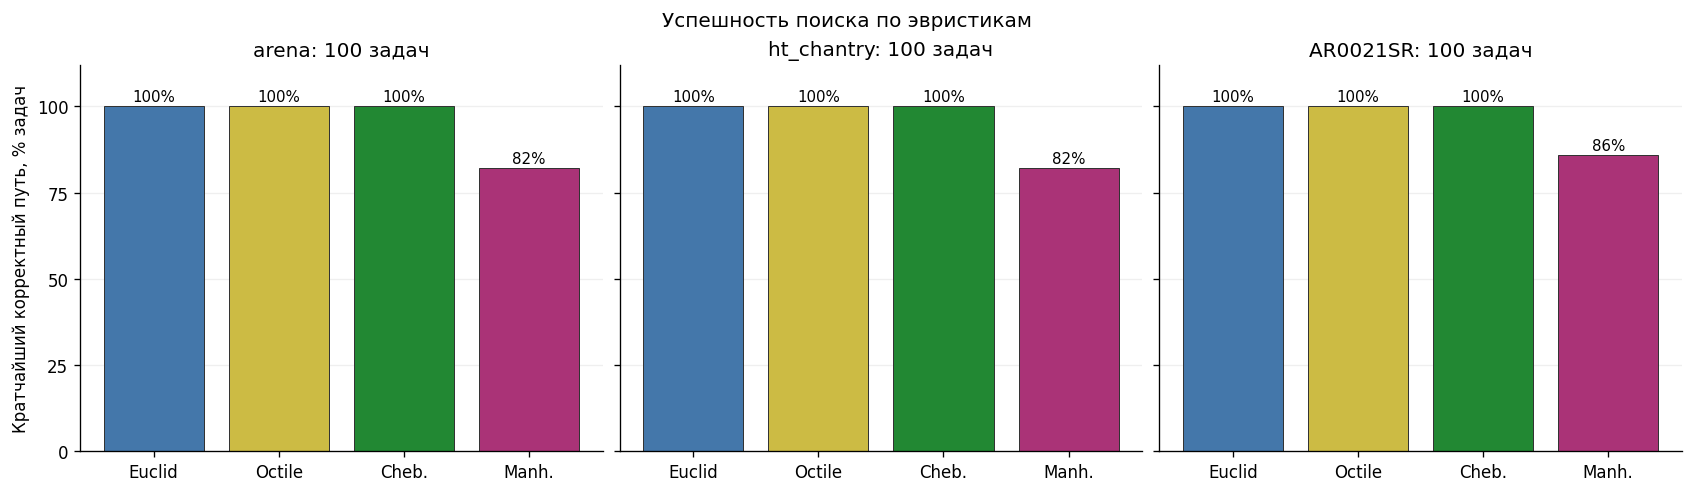

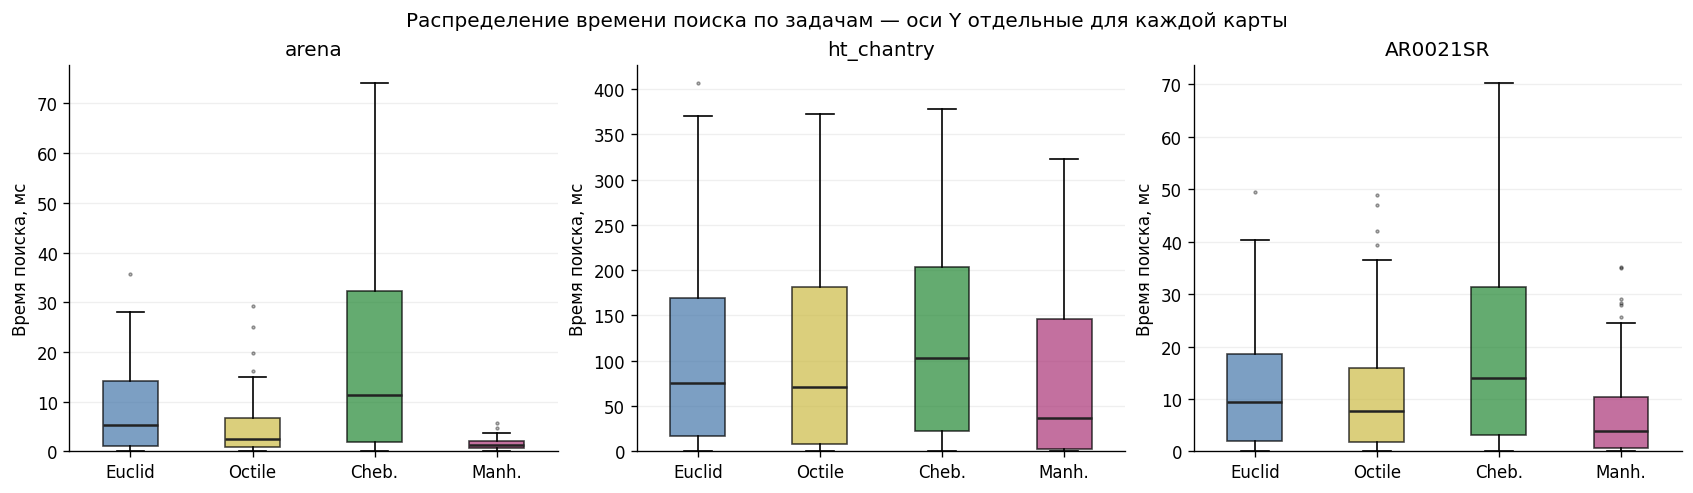

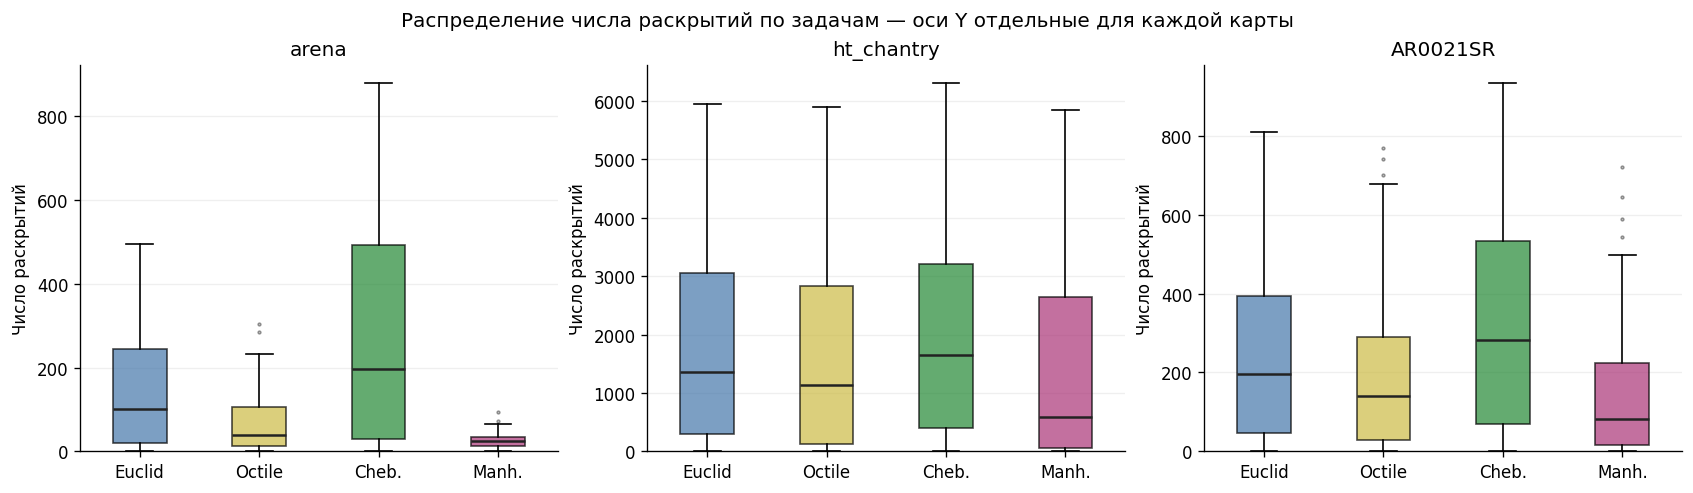

In [22]:
def plot_benchmark(per_task):
    map_names = [spec['name'] for spec in MAP_SPECS]
    short_labels = ['Euclid', 'Octile', 'Cheb.', 'Manh.']
    colors = [HEURISTIC_COLORS[name] for name in HEURISTIC_ORDER]

    fig, axes = plt.subplots(1, len(map_names), figsize=(14, 4), constrained_layout=True, sharey=True)
    for ax, map_name in zip(np.atleast_1d(axes), map_names):
        part = per_task[per_task['map'] == map_name]
        rates = [100 * part.loc[part['heuristic'] == name, 'optimal'].mean() for name in HEURISTIC_ORDER]
        bars = ax.bar(short_labels, rates, color=colors, edgecolor='#333333', linewidth=.6)
        for bar, rate in zip(bars, rates):
            ax.text(bar.get_x() + bar.get_width() / 2, rate + 1.5, f'{rate:.0f}%', ha='center', fontsize=9)
        ax.set_title(f'{map_name}: {part.task_id.nunique()} задач')
        ax.set_ylim(0, 112)
        ax.set_yticks([0, 25, 50, 75, 100])
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
    np.atleast_1d(axes)[0].set_ylabel('Кратчайший корректный путь, % задач')
    fig.suptitle('Успешность поиска по эвристикам')
    plt.show()

    for metric, ylabel, title in [
        ('time_ms', 'Время поиска, мс', 'Распределение времени поиска по задачам'),
        ('expansions', 'Число раскрытий', 'Распределение числа раскрытий по задачам'),
    ]:
        fig, axes = plt.subplots(1, len(map_names), figsize=(14, 4), constrained_layout=True)
        for ax, map_name in zip(np.atleast_1d(axes), map_names):
            part = per_task[per_task['map'] == map_name]
            data = [part.loc[part['heuristic'] == name, metric].to_numpy() for name in HEURISTIC_ORDER]
            artists = ax.boxplot(data, patch_artist=True, medianprops={'color': '#222222', 'linewidth': 1.5},
                                 flierprops={'marker': '.', 'markersize': 3, 'alpha': .45})
            for box, color in zip(artists['boxes'], colors):
                box.set_facecolor(color)
                box.set_alpha(.7)
            ax.set_xticks(range(1, 5), short_labels)
            ax.set_title(map_name)
            ax.set_ylabel(ylabel)
            ax.set_ylim(bottom=0)
            ax.grid(axis='y', alpha=.2)
        fig.suptitle(title + ' — оси Y отдельные для каждой карты')
        plt.show()


plot_benchmark(results)

## Пример найденного маршрута

Маршрут для одной из выбранных задач на `arena`, найденный с Octile.
Построение рисунка не входит во время поиска.

Зелёным обозначен старт, красным — цель, голубым — маршрут; серые клетки показывают область поиска.

In [23]:
def draw(grid_map: Map,
         start: Node = None,
         goal: Node = None,
         path: Iterable[Node] = None,
         nodes_discovered: Iterable[Node] = None,
         nodes_expanded: Iterable[Node] = None,
         nodes_reexpanded: Iterable[Node] = None):
    scale = 5
    height, width = grid_map.get_size()
    h_im = height * scale
    w_im = width * scale
    im = Image.new('RGB', (w_im, h_im), color = 'white')
    draw = ImageDraw.Draw(im)

    for i in range(height):
        for j in range(width):
            if(not grid_map.traversable(i, j)):
                draw.rectangle((j * scale, i * scale, (j + 1) * scale - 1, (i + 1) * scale - 1), fill=( 70, 80, 80 ))

    if nodes_discovered is not None:
        for node in nodes_discovered:
            draw.rectangle((node.j * scale, node.i * scale, (node.j + 1) * scale - 1, (node.i + 1) * scale - 1), fill=(213, 219, 219), width=0)

    if nodes_expanded is not None:
        for node in nodes_expanded:
            draw.rectangle((node.j * scale, node.i * scale, (node.j + 1) * scale - 1, (node.i + 1) * scale - 1), fill=(131, 145, 146), width=0)

    if nodes_reexpanded is not None:
        for node in nodes_reexpanded:
                draw.rectangle((node.j * scale, node.i * scale, (node.j + 1) * scale - 1, (node.i + 1) * scale - 1), fill=(255, 145, 146), width=0)

    if path is not None:
        for step in path:
            if (step is not None):
                if (grid_map.traversable(step.i, step.j)):
                    draw.rectangle((step.j * scale, step.i * scale, (step.j + 1) * scale - 1, (step.i + 1) * scale - 1), fill=(52, 152, 219), width=0)
                else:
                    draw.rectangle((step.j * scale, step.i * scale, (step.j + 1) * scale - 1, (step.i + 1) * scale - 1), fill=(230, 126, 34), width=0)

    if (start is not None) and (grid_map.traversable(start.i, start.j)):
        draw.rectangle((start.j * scale, start.i * scale, (start.j + 1) * scale - 1, (start.i + 1) * scale - 1), fill=(40, 180, 99), width=0)

    if (goal is not None) and (grid_map.traversable(goal.i, goal.j)):
        draw.rectangle((goal.j * scale, goal.i * scale, (goal.j + 1) * scale - 1, (goal.i + 1) * scale - 1), fill=(231, 76, 60), width=0)

    _, ax = plt.subplots(dpi=150)
    ax.axes.xaxis.set_visible(False)
    ax.axes.yaxis.set_visible(False)
    plt.imshow(np.asarray(im))
    plt.show()

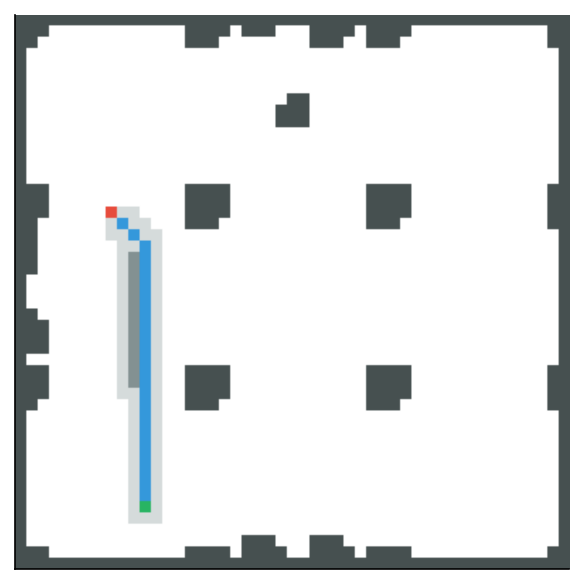

Стоимость маршрута: 27.24264 Эталон: 27.24264069


In [24]:
demo_map_name = MAP_SPECS[0]['name']
demo_task = tasks_by_map[demo_map_name][TASKS_PER_MAP // 2]
demo_result = astar_reexpansion(
    maps[demo_map_name], *demo_task['start'], *demo_task['goal'], octile_distance, SearchTreePQDReexp,
)
if demo_result[0]:
    demo_path, demo_length = make_path(demo_result[1])
    draw(maps[demo_map_name], Node(*demo_task['start']), Node(*demo_task['goal']), demo_path, *demo_result[4:])
    print('Стоимость маршрута:', round(demo_length, 5), 'Эталон:', demo_task['optimal_length'])
else:
    print('Путь не найден')

## 9. Выводы

1. Все эвристики, кроме Манхэттена, нашли кратчайший путь во всех тестах. Манхэттен хоть и самый быстрый в среднем, но не всегда находит именно кратчайший путь.
2. Наименьшее число раскрытий среди допустимых эвристик — у диагональной.
3. Соответственно, она обычно и самая быстрая среди них. На ht_chantry по среднему времени немного быстрее оказался Евклид, поэтому полного совпадения времени и числа раскрытий всё же нет.
4. Разброс довольно большой, особенно у Чебышёва. Могу предположить, что это связано с тем, что он довольно грубо оценивает расстояние и занижает реальную стоимость: диагональный шаг для него стоит 1. Одно среднее скрывает разницу между задачами: на одних путь находится быстро, а на других приходится раскрывать гораздо больше клеток.
5. Да, сравнение меняется в зависимости от карты. Это может быть связано с тем, какие на ней пути: насколько часто нужны обходы, сколько диагональных и прямых участков и насколько маршруты петляют.
6. Из ограничений: не факт, что задачи на всех картах были равномерно выбраны по сложности. Сейчас отбор шёл по длине пути, но длинный путь не всегда сложно найти. Поэтому результаты могут зависеть от выбранного набора задач, хотя для всех эвристик он был одинаковым. Ещё можно было взять больше карт и сделать несколько повторов замеров времени.

## Источники

- [MovingAI: наборы задач поиска пути](https://movingai.com/benchmarks/grids.html).
- [Форматы карт, сценариев и правила движения](https://movingai.com/benchmarks/formats.html).
- N. Sturtevant. *Benchmarks for Grid-Based Pathfinding*. IEEE Transactions on
  Computational Intelligence and AI in Games, 4(2), 144–148, 2012.
- [Open Data Commons Attribution License](https://opendatacommons.org/licenses/by/1-0/).
- Адреса исходных архивов, дата получения и SHA-256: `data/sources.json`.